In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sc

In [ ]:
nom_methode = ("Options asiatiques : Euler Implicite (upwind)")

# Parametres principaux
T = 1.0        # echeance
r = 1.0        # taux de l'actif sans risque
sigma = 2.0    # volatilite du sous-jacent

# Parametres de discretisation
N = 2**10+1   # pas dans le maillage en espace
J = 2**10+1   # pas dans le maillage en temps

# essayer avec N = 10, J = 225 ou J = 220 pour apprecier la stabilite

xmin, xmax = -10.0, 10.0  # bords du domaine coupe
x_plotted = np.linspace(xmin, xmax, N)  # maillage en espace
x=x_plotted[1:N-1]

# pas de discretisation en espace et en temps
h = x[1]-x[0]
k = T / J



In [ ]:
#Conditions aux limites
def a(t):
    return -np.exp(-r*t)
def b(t):
    return 1/(r*T)-1-np.exp(-r*t)/(r*T)

# Conditions initiales
def g(x):
    #return -1-x
    return np.maximum(-1-x,0)

In [ ]:
#Matrice A
def mat_A(N,h,sigma,r,T,x):
    A1=(np.diag(-2*x**2)+np.diag(x[1:]**2,k=-1)+np.diag(x[:N-3]**2,k=1))*(-sigma**2/(2*h**2))
    A2=(np.diag(x[:N-3],k=1)-np.diag(x[1:],k=-1))*(r/(2*h))
    A3=(np.diag(np.ones((N-3)),k=1)-np.diag(np.ones((N-3)),k=-1))*(1/(2*h*T))
    return A1+A2+A3
#Vecteur l
def vect_l(t,N,h,sigma,r,T,x):
    l=np.zeros(N-2)
    l[0]=-((1/(2*h**2))*sigma**2*x[0]**2+1/(2*h)*(r*x[0]+1/T))*(a(t)*xmin+b(t))
    return l

In [ ]:
#Fonction de transition
def Time_transition(A,nom_methode,x,l1,l2,N):
    if nom_methode=="Options asiatiques : Euler Explicite (upwind)":
        return (np.eye(N-2)-k*A).dot(x)-k*l1
    elif nom_methode=="Options asiatiques : Euler Implicite (upwind)":
        return np.linalg.solve(np.eye(N-2)+k*A,x-k*l2)
    elif nom_methode=="Options asiatiques : Crank-Nicolson (upwind)":
        return np.linalg.solve(np.eye(N-2)+k/2*A,(np.eye(N-2)-k/2*A).dot(x)-k/2*(l1+l2))

In [ ]:
#solution exacte_ish

N1 = 2**10+1
J1 = 2**10+1
k1=T/2**10
x1_plotted = np.linspace(xmin, xmax, N1)  # maillage en espace
h1 = x1_plotted[1]-x1_plotted[0]
x1 = x1_plotted[1:N1-1]
F = np.zeros((N1,J1))
f1_0=g(x1)
f1_j=g(x1)
F = np.zeros((N1,J1))
F[:,0]= np.concatenate((np.array([a(0)*xmin+b(0)]),f1_0,np.array([0])),axis=None)
#Boucle temporelle
for j in range(J1):
    l11=vect_l(j*k1,N1,h1,sigma,r,T,x1)
    l12=vect_l((j+1)*k1,N1,h1,sigma,r,T,x1)
    A1=mat_A(N1,h1,sigma,r,T,x1)
    f1_j=Time_transition(A1,nom_methode,f1_j,l11,l12,N1)
    F[:,j] = np.concatenate((np.array([a(k1*j)*xmin+b(k1*j)]),f1_j,np.array([0])),axis=None)


In [ ]:
f_0=g(x)
f_j=g(x)
#Boucle temporelle
s=1 #constante de stabilité
for j in range(J):
    l1=vect_l(j*k,N,h,sigma,r,T,x)
    l2=vect_l((j+1)*k,N,h,sigma,r,T,x)
    A=mat_A(N,h,sigma,r,T,x)
    f_j=Time_transition(A,nom_methode,f_j,l1,l2,N)
    #Stabilité
    #if np.linalg.norm(f_j)/np.linalg.norm(f_0)>s:
     #   s=np.linalg.norm(f_j)/np.linalg.norm(f_0)

    #visualisation de la solution
    if (j+1)%50==0:
        f_j_plotted = np.concatenate((np.array([a(k*j)*xmin+b(k*j)]),f_j,np.array([0])),axis=None)
        plt.plot(x_plotted,f_j_plotted,color="blue",linestyle="dashed",linewidth=1)
#réglages de la visualisation
valin,  = plt.plot(x_plotted, np.concatenate((np.array([a(0)*xmin+b(0)]),f_0,np.array([0])),axis=None),  color='orange', linestyle='solid', linewidth=2)
valfin, = plt.plot(x_plotted, np.concatenate((np.array([a(k*J)*xmin+b(k*J)]),f_j,np.array([0])),axis=None),  color='blue', linestyle='solid', linewidth=2)
plt.xlabel("x")
plt.ylabel("Valeur de f")


#solution exacte
#val_exacte,=plt.plot(x_plotted,a(k*J)*x_plotted+b(k*J),color="red",linewidth=1)
plt.legend([valin, valfin], ["Valeur à l'écheance", "Valeur (approx)"])
#plt.legend([valin, valfin,val_exacte], ["Valeur à l'écheance", "Valeur (approx)","Solution exacte"])
#print("La constante de stabilité est : ",s)

NameError: name 'g' is not defined

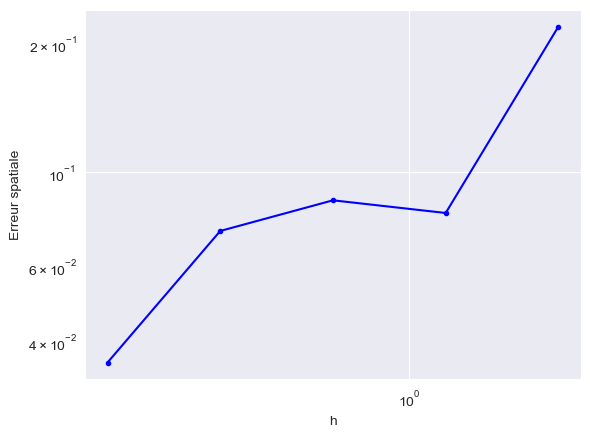

In [ ]:
#erreur spatiale
Nt = 5
Err = np.zeros(Nt)
H = np.zeros(Nt)
J=2**10+1
k=T/2**10
for i in range(Nt):
    h = (xmax - xmin) / (2**(i+3))
    N =(2**(i+3))+1
    x_plotted = np.linspace(xmin, xmax, N)  # maillage en espace
    x = x_plotted[1:N-1]
    H[i] = h
    f_0=g(x)
    f_j=g(x)
    s=1 #constante de stabilité
    E_h = 0
    #Boucle temporelle
    for j in range(J):
        l1=vect_l(j*k,N,h,sigma,r,T,x)
        l2=vect_l((j+1)*k,N,h,sigma,r,T,x)
        A=mat_A(N,h,sigma,r,T,x)
        f_j=Time_transition(A,nom_methode,f_j,l1,l2,N)
        #erreur
        f_j_plotted = np.concatenate((np.array([a(k*j)*xmin+b(k*j)]),f_j,np.array([0])),axis=None)
        E_h = max(E_h, np.linalg.norm(f_j_plotted - np.array([F[p,j] for p in range(N1) if p%(2**(7-i))==0]), np.inf))
        Err[i] = E_h

#plt.figure(figsize=(12,9))
plt.loglog(H, Err, marker = '.', color='blue')
plt.xlabel("h")
plt.ylabel("Erreur spatiale")
#plt.loglog(H, H/H[-1]*Err[-1], color='red')
plt.show()

In [ ]:
np.polyfit(np.log(H),np.log(Err),1)[0]

0.5371188640951589

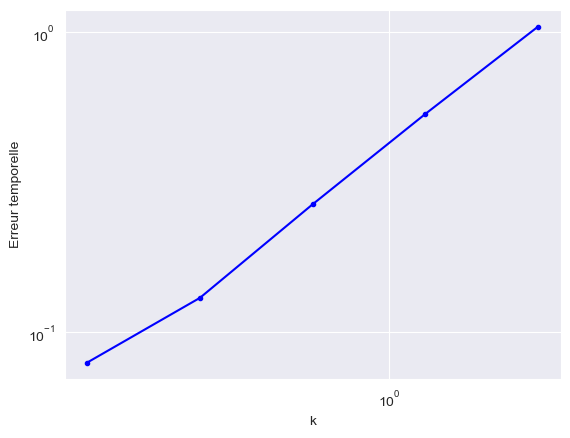

In [ ]:
#erreur temporelle

Nt = 5
Err = np.zeros(Nt)
K = np.zeros(Nt)
N=2**10+1
h=(xmax-xmin)/2**10

for i in range(Nt):
    J = (2**(i+3))+1
    k = T / (2**(i+3))
    x_plotted = np.linspace(xmin, xmax, N)  # maillage en espace
    x = x_plotted[1:N-1]
    K[i] = k
    f_0=g(x)
    f_j=g(x)
    E_k = 0
     #Boucle temporelle
    for j in range(J):
        l1=vect_l(j*k,N,h,sigma,r,T,x)
        l2=vect_l((j+1)*k,N,h,sigma,r,T,x)
        A=mat_A(N,h,sigma,r,T,x)
        f_j=Time_transition(A,nom_methode,f_j,l1,l2,N)
        #erreur
        f_j_plotted = np.concatenate((np.array([a(k*j)*xmin+b(k*j)]), f_j, np.array([0])),axis=None)
        E_k = max(E_k, np.linalg.norm(f_j_plotted - F[:,j*(2**(7-i))], np.inf))
        #np.array([F[,p] for p in range(J1) if p%(2**(7-i))==0])
        Err[i] = E_k

#plt.figure(figsize=(12,9))
plt.loglog(H, Err, marker = '.', color='blue')
#plt.loglog(H, H/H[-1]*Err[-1], color='red')
plt.xlabel("k")
plt.ylabel("Erreur temporelle")
plt.show()

In [ ]:
np.polyfit(np.log(K),np.log(Err),1)[0]

0.9475236752309274

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


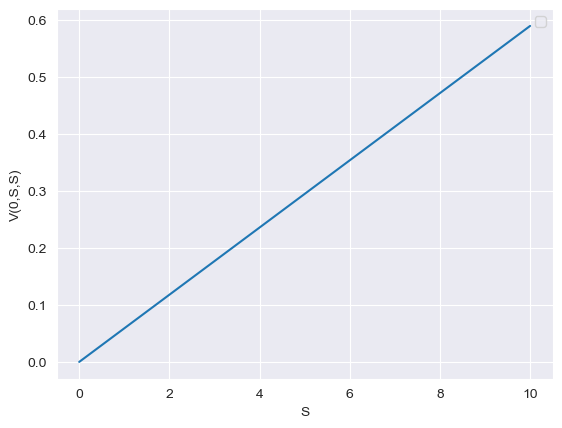

In [ ]:
S=np.linspace(0,10,11)
plt.plot(S,S*f_j_plotted[int((N-1)/2)])
plt.xlabel("S")
plt.ylabel("V(0,S,S)")
plt.legend()